# Introduction to Clustering & Feature Scaling

Clustering adalah teknik unsupervised learning yang mengelompokkan data berdasarkan kemiripan struktur intrinsiknya tanpa menggunakan variabel target (label).

Pentingnya Z-Score Normalization (StandardScaler):
Algoritma berbasis jarak sangat sensitif terhadap skala fitur. Jika suatu fitur memiliki rentang numerik yang jauh lebih besar dibanding fitur lain, fitur tersebut akan mendominasi perhitungan jarak Euclidean. Skalasi Z-score mengubah setiap fitur $x$ menjadi:
$$z = \frac{x - \mu}{\sigma}$$
di mana $\mu$ adalah rata-rata (mean) dan $\sigma$ adalah standar deviasi. Setelah transformasi, setiap fitur memiliki rata-rata $0$ dan standar deviasi $1$.

Dataset shape: (300, 2)
Feature 1 range: [-1.420, 1.513]
Feature 2 range: [-1.408, 1.301]


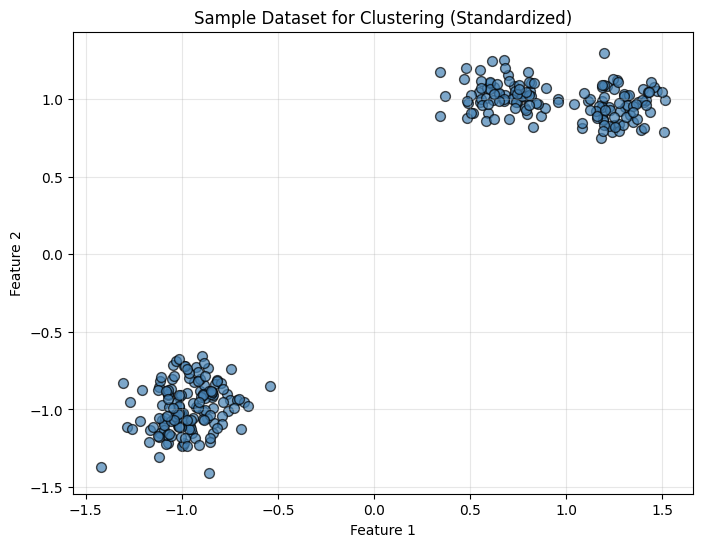

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# 1. Membuat dataset sintetis dengan 4 kluster
X, _ = make_blobs(
    n_samples=300, centers=4,
    cluster_std=0.60, random_state=2024
)

# 2. Melakukan Z-Score Normalization
X = StandardScaler().fit_transform(X)

print(f"Dataset shape: {X.shape}")
print(f"Feature 1 range: [{X[:, 0].min():.3f}, {X[:, 0].max():.3f}]")
print(f"Feature 2 range: [{X[:, 1].min():.3f}, {X[:, 1].max():.3f}]")

# 3. Visualisasi Data Mentah
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, color='steelblue', edgecolor='k', alpha=0.7)
plt.title("Sample Dataset for Clustering (Standardized)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, alpha=0.3)
plt.show()

- make_blobs: Menghasilkan $300$ sampel data yang terbagi ke dalam $4$ pusat kluster sintetis. Karakter _ digunakan untuk membuang label target asli karena dalam skenario unsupervised learning, label tidak tersedia.

- StandardScaler(): Memastikan kedua fitur berada pada skala yang seimbang (rentang sekitar $-1.4$ hingga $+1.5$).

- Grafik Visualisasi: Plot menyajikan sebaran $300$ titik data mentah pada ruang 2D. Terlihat jelas $4$ area pengelompokan alami, dengan 2 kelompok di kiri bawah dan 2 kelompok di kanan atas.

# K-Means Clustering & The Elbow Method

K-Means membagi data menjadi $K$ kluster dengan cara meminimalkan Inertia (within-cluster sum-of-squares):
$$\text{Inertia} = \sum_{i=1}^{n} \min_{\boldsymbol{\mu}_j \in C} (\Vert{}\mathbf{x}_i - \boldsymbol{\mu}_j\Vert{}^2)$$
di mana $\boldsymbol{\mu}_j$ adalah titik pusat (centroid) kluster $j$.

Tahapan Algoritma K-Means:
1. Inisialisasi $K$ pusat kluster (menggunakan metode $K$-Means++ agar posisi awal saling berjauhan).
2. Asosiasikan setiap titik data ke centroid terdekat berdasarkan jarak Euclidean.
3. Perbarui posisi centroid berdasarkan rata-rata posisi seluruh titik dalam kluster tersebut.
4. Ulangi langkah 2 dan 3 hingga posisi centroid konvergen (tidak berubah).

Metode Elbow:
Menjalankan K-Means untuk rentang nilai $K$ (misal $1$ hingga $9$), lalu memplot nilai Inertia terhadap $K$. Titik "siku" (elbow) pada grafik menunjukkan nilai $K$ optimal di mana penambahan kluster setelahnya tidak lagi memberikan penurunan inertia secara signifikan.

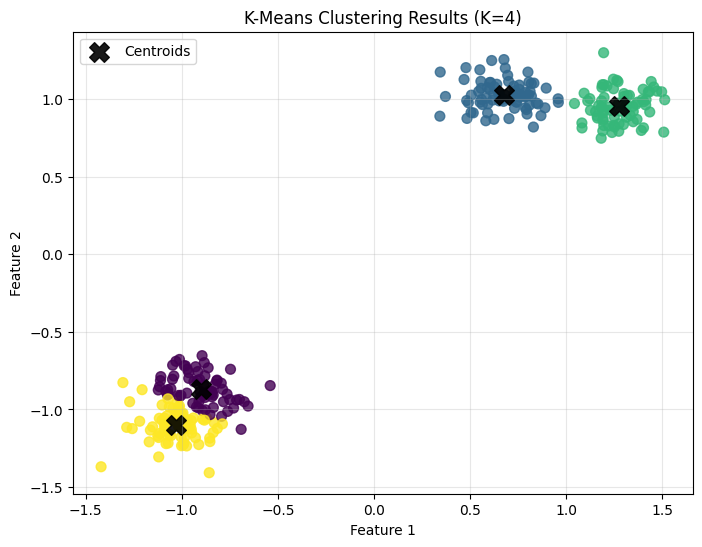

Cluster sizes: [71 77 73 79]
Inertia: 7.295
Converged in 4 iterations



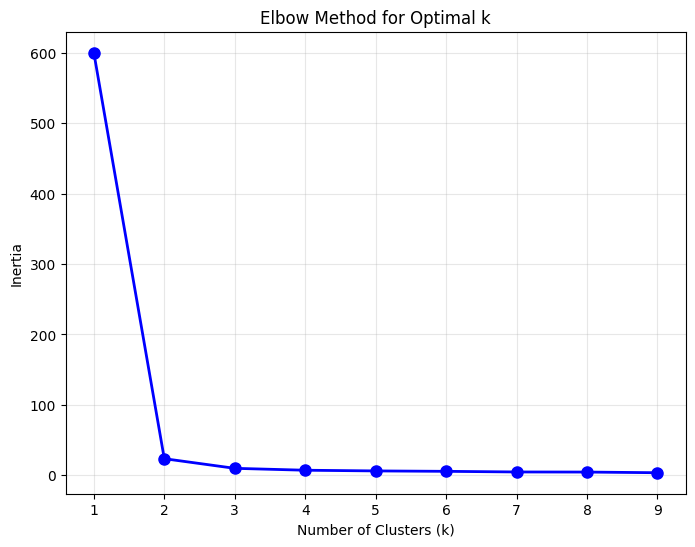

k=1: inertia=600.000
k=2: inertia=23.679
k=3: inertia=9.993
k=4: inertia=7.295
k=5: inertia=6.305
k=6: inertia=5.724
k=7: inertia=4.827
k=8: inertia=4.685
k=9: inertia=3.752


In [2]:
from sklearn.cluster import KMeans

# A. Pelatihan K-Means dengan K=4
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

# Visualisasi Hasil K-Means (K=4)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.9, marker='X', label='Centroids')
plt.title("K-Means Clustering Results (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Cluster sizes: {np.bincount(y_kmeans)}")
print(f"Inertia: {kmeans.inertia_:.3f}")
print(f"Converged in {kmeans.n_iter_} iterations\n")

# B. Metode Elbow untuk Menentukan K Optimal
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

# Visualisasi Grafik Elbow
plt.figure(figsize=(8, 6))
plt.plot(k_values, inertia, 'bo-', linewidth=2, markersize=8)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.grid(True, alpha=0.3)
plt.show()

for k, iner in zip(k_values, inertia):
    print(f"k={k}: inertia={iner:.3f}")

- Visualisasi Hasil (K=4): K-Means membagi data menjadi 4 kluster seimbang (ukuran: $71, 77, 73, 79$) dengan nilai inertia sebesar $7.295$ dan konvergen hanya dalam $4$ iterasi. Simbol tanda silang hitam (X) menandakan centroid akhir.

- Grafik Elbow: Terjadi penurunan inertia paling drastis dari $K=1$ ($600.0$) ke $K=2$ ($23.679$), dilanjutkan penurunan hingga $K=4$ ($7.295$). Setelah $K=4$, penurunan inertia menjadi sangat landai ($K=5$ hanya $6.305$). Ini mengonfirmasi secara visual bahwa lekukan siku berada tepat pada $K=4$.

# Hierarchical Clustering & Dendrograms

Hierarchical Agglomerative Clustering (HAC) membangun hierarki kluster secara bottom-up:
1. Setiap titik data diawali sebagai kluster tunggalnya sendiri ($N$ kluster).
2. Hitung jarak antar kluster dan gabungkan dua kluster terdekat.
3. Ulangi proses penggabungan secara berurutan hingga seluruh data bergabung menjadi 1 kluster besar.

Kriteria Linkage:
- Ward (Default): Meminimalkan varians total di dalam kluster yang digabungkan. Sangat baik untuk kluster yang padat dan berukuran seimbang.
- Complete: Menggunakan jarak maksimum antar titik di dua kluster.
- Average: Menggunakan rata-rata jarak antar seluruh pasangan titik di dua kluster.
- Single: Menggunakan jarak minimum antar titik di dua kluster (dapat menangkap bentuk non-konveks).

Dendrogram: Diagram pohon yang menampilkan riwayat lengkap urutan penggabungan kluster beserta jarak (height) saat penggabungan terjadi.

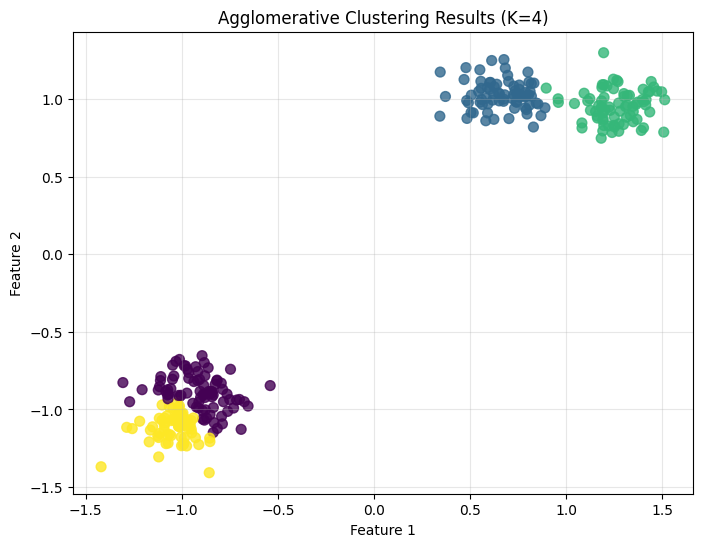

Agglomerative Cluster sizes: [82 74 76 68]



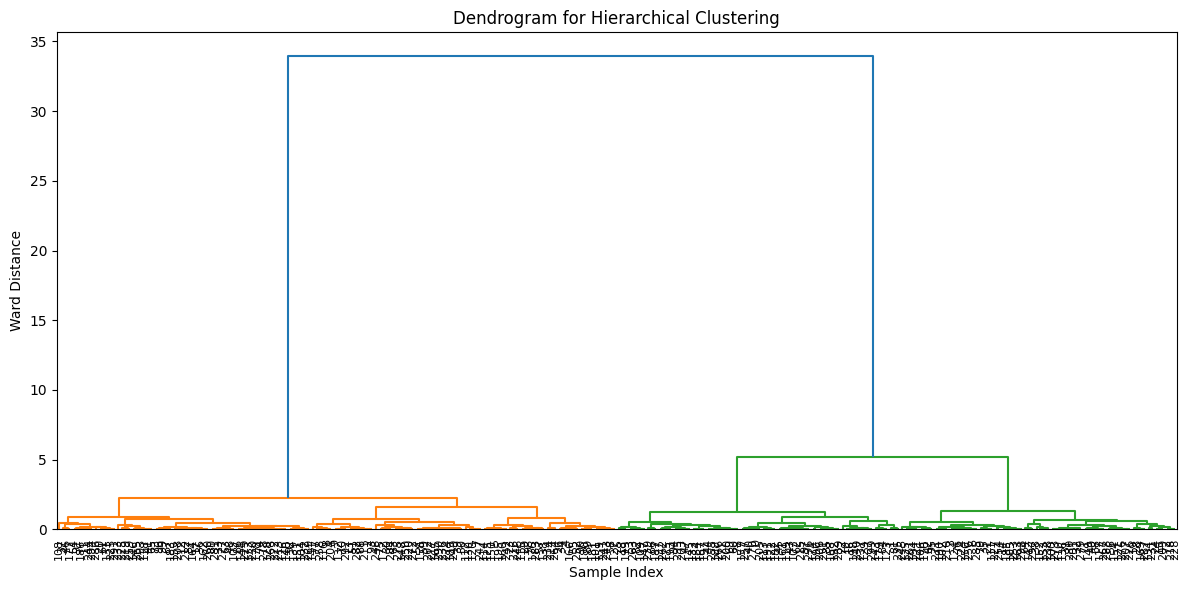

Max merge distance (final merge): 33.951
Second-to-last merge distance: 5.208


In [3]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# A. Pelatihan Agglomerative Clustering (K=4)
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50, alpha=0.8)
plt.title("Agglomerative Clustering Results (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Agglomerative Cluster sizes: {np.bincount(y_agg)}\n")

# B. Membuat dan Memplot Dendrogram
linked = linkage(X, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

print(f"Max merge distance (final merge): {linked[-1, 2]:.3f}")
print(f"Second-to-last merge distance: {linked[-2, 2]:.3f}")

- Visualisasi Agglomerative: Menghasilkan ukuran kluster $82, 74, 76, 68$. Karena keputusan penggabungan pada HAC bersifat serakah (greedy) dan permanen, pembagian ukurannya sedikit berbeda dibanding K-Means.

- Grafik Dendrogram: Sumbu Y menunjukkan jarak penggabungan. Garis vertikal panjang antara penggabungan terakhir (jarak $33.951$) dan penggabungan sebelumnya (jarak $5.208$) menunjukkan lompatan jarak yang besar. Jika kita memotong dendrogram secara horisontal pada rentang jarak $10$–$30$, garis memotong $4$ cabang utama, yang mengonfirmasi bahwa $K=4$ adalah jumlah kluster paling alami.

# Density-Based Clustering with DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) mengelompokkan data berdasarkan kerapatan lokal tanpa mengasumsikan bentuk kluster bulat (konveks) dan tanpa perlu menentukan jumlah $K$ di awal.

Tiga Kategori Titik Data pada DBSCAN:
1. Core Point: Titik yang memiliki minimal min_samples tetangga dalam radius $\epsilon$ (eps).
2. Border Point: Titik yang bukan core point, tetapi berada dalam radius $\epsilon$ dari suatu core point.
3. Noise / Outlier: Titik yang bukan core point maupun border point (diberi label $-1$).

Grafik k-Distance: Digunakan untuk memilih nilai $\epsilon$ (eps) secara objektif. Hitung jarak setiap titik ke tetangga terdekat ke-$k$ (k = min_samples), urutkan jarak secara membesar, lalu plot grafiknya. Titik siku (elbow) pada plot $k$-distance menunjukkan ambang batas $\epsilon$ yang optimal.

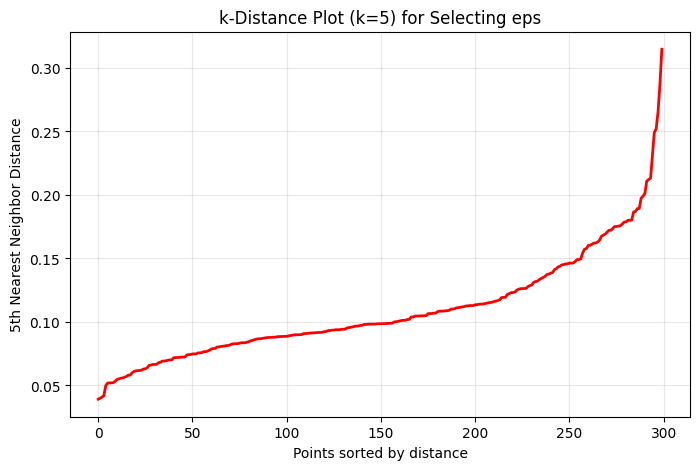

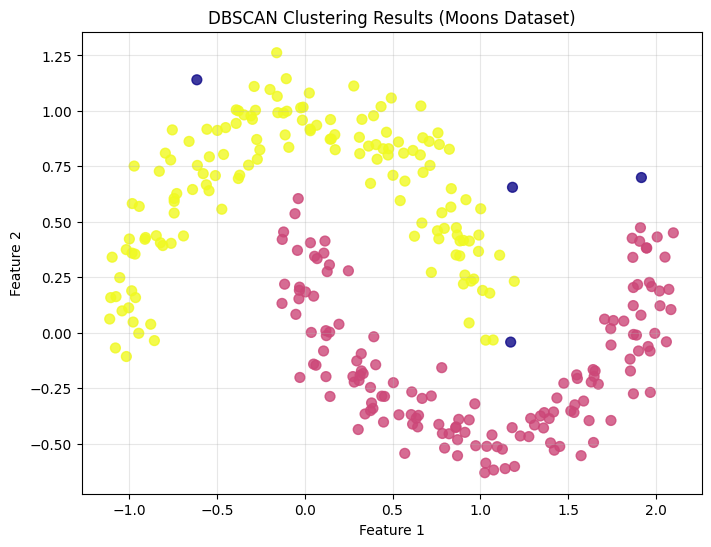

Number of clusters found: 2
Noise points: 4 (1.3% of data)


In [4]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.neighbors import NearestNeighbors

# 1. Membuat Data Bentuk Bulan Sabit (Non-Konveks)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)

# 2. Grafik k-Distance untuk Menentukan eps
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_moons)
distances, indices = neighbors_fit.kneighbors(X_moons)
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))
plt.plot(distances, 'r-', linewidth=2)
plt.title("k-Distance Plot (k=5) for Selecting eps")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.grid(True, alpha=0.3)
plt.show()

# 3. Pelatihan DBSCAN (eps=0.2, min_samples=5)
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X_moons)

# Visualisasi Hasil DBSCAN
plt.figure(figsize=(8, 6))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_db, cmap='plasma', s=50, alpha=0.8)
plt.title("DBSCAN Clustering Results (Moons Dataset)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, alpha=0.3)
plt.show()

n_clusters_ = len(set(y_db)) - (1 if -1 in y_db else 0)
n_noise_ = list(y_db).count(-1)
print(f"Number of clusters found: {n_clusters_}")
print(f"Noise points: {n_noise_} ({n_noise_/len(y_db)*100:.1f}% of data)")

- Grafik k-Distance: Menampilkan kenaikan jarak yang tajam setelah indeks titik ke-280 (rentang jarak $0.15$ hingga $0.20$). Titik siku ini memisahkan daerah padat di dalam kluster dari daerah renggang (noise).

- Visualisasi DBSCAN: DBSCAN berhasil memisahkan $2$ kluster berbentuk bulan sabit secara sempurna dan mendeteksi $4$ titik noise (titik berwarna gelap terisolasi di luar bentuk bulan). Algoritma konvensional seperti K-Means akan gagal pada struktur geometri seperti ini.

# Cluster Evaluation Metrics

Evaluasi clustering memadukan metrik internal (tanpa butuh label target asli) dan metrik eksternal (jika data memiliki label pembanding):
1. Silhouette Score (Internal, $-1$ s.d. $+1$, semakin tinggi semakin baik):
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

di mana $a(i)$ adalah rata-rata jarak intra-kluster dan $b(i)$ adalah rata-rata jarak ke kluster tetangga terdekat. Skor $> 0.5$ menandakan pemisahan kluster yang baik.

2. Davies-Bouldin Index (Internal, $\ge 0$, semakin kecil semakin baik):
Mengukur rasio rata-rata sebaran di dalam kluster (spread) terhadap jarak antar pusat kluster (gap).

3. Adjusted Rand Index / ARI (Eksternal, $-1$ s.d. $+1$, $1$ = cocok sempurna):
Mengukur tingkat kesesuaian antara label prediksi kluster dengan label kebenaran asli (ground truth), terlepas dari perbedaan penamaan nomor kelas.

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# 1. Regenerasi Dataset Blobs dengan Label Asli
X_eval, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
kmeans_eval = KMeans(n_clusters=4, random_state=2024)
y_pred = kmeans_eval.fit_predict(X_eval)

# 2. Perhitungan Metrik Evaluasi
sil_score = silhouette_score(X_eval, y_pred)
db_index = davies_bouldin_score(X_eval, y_pred)
ari_score = adjusted_rand_score(y_true, y_pred)

print(f"Silhouette Score    : {sil_score:.3f}  (Mendekati 1 = Sangat Baik)")
print(f"Davies-Bouldin Index: {db_index:.3f}  (Mendekati 0 = Sangat Baik)")
print(f"Adjusted Rand Index : {ari_score:.3f}  (Mendekati 1 = Sangat Cocok dengan Ground Truth)")

Silhouette Score    : 0.534  (Mendekati 1 = Sangat Baik)
Davies-Bouldin Index: 0.702  (Mendekati 0 = Sangat Baik)
Adjusted Rand Index : 0.814  (Mendekati 1 = Sangat Cocok dengan Ground Truth)


- Silhouette Score ($0.534$): Menunjukkan pemisahan kluster yang solid secara keseluruhan.

- Davies-Bouldin Index ($0.702$): Bernilai rendah (di bawah $1.0$), mengonfirmasi bahwa sebaran di dalam kluster jauh lebih rapat dibanding jarak antar centroid.

- Adjusted Rand Index ($0.814$): Menunjukkan kesesuaian tinggi ($> 81\%$) antara kluster hasil K-Means dengan struktur ground truth buatan make_blobs.

# Choosing the Right Clustering Algorithm

Pemilihan algoritma clustering yang tepat bergantung pada geometri dan distribusi data:
- Isotropic Gaussian Blobs (Kluster bulat konveks): Sangat cocok untuk K-Means, Hierarchical (Ward), atau GMM.
- Interleaving Moons (Bentuk kurva memanjang/non-konveks): Sangat cocok untuk DBSCAN atau Spectral Clustering.
- Nested Circles (Kluster melingkar sepusat): Sangat cocok untuk DBSCAN atau Spectral Clustering.

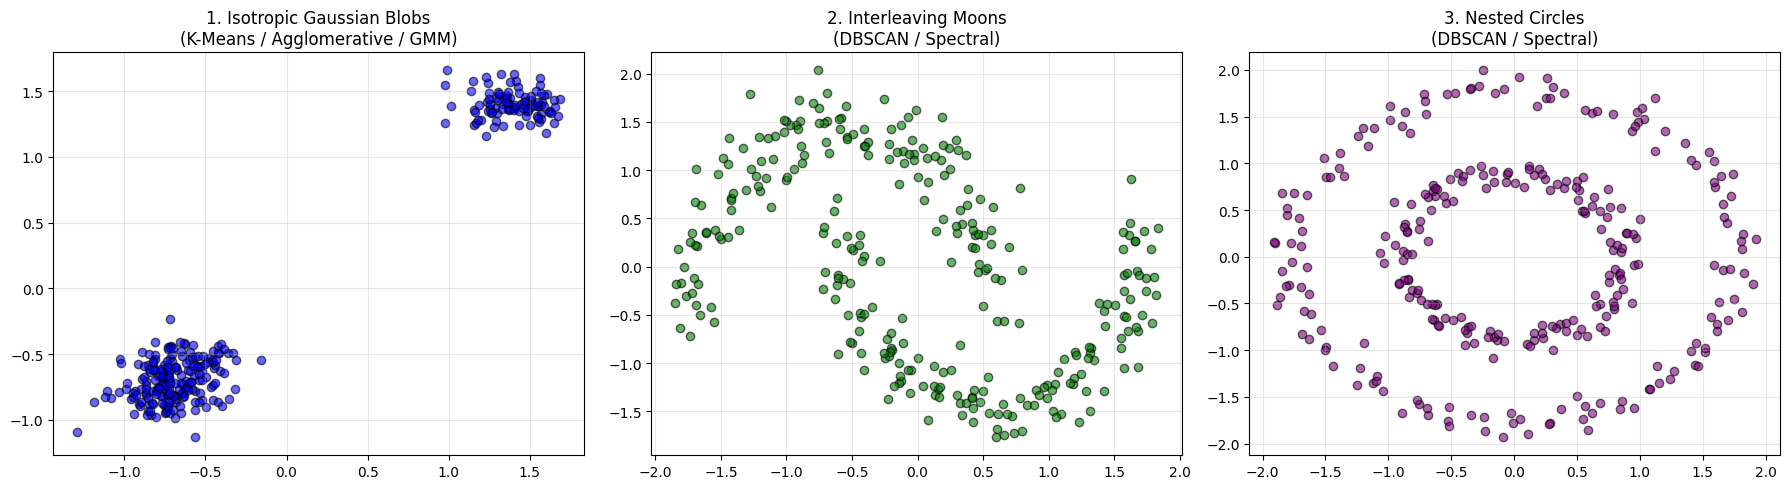

In [6]:
from sklearn.datasets import make_circles

# Generate 3 Geometri Data Berbeda
X_blobs_geo, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons_geo, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles_geo, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs_geo = StandardScaler().fit_transform(X_blobs_geo)
X_moons_geo = StandardScaler().fit_transform(X_moons_geo)
X_circles_geo = StandardScaler().fit_transform(X_circles_geo)

# Plot Visualisasi 3 Geometri
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].scatter(X_blobs_geo[:, 0], X_blobs_geo[:, 1], c='blue', alpha=0.6, edgecolor='k')
axs[0].set_title("1. Isotropic Gaussian Blobs\n(K-Means / Agglomerative / GMM)")

axs[1].scatter(X_moons_geo[:, 0], X_moons_geo[:, 1], c='green', alpha=0.6, edgecolor='k')
axs[1].set_title("2. Interleaving Moons\n(DBSCAN / Spectral)")

axs[2].scatter(X_circles_geo[:, 0], X_circles_geo[:, 1], c='purple', alpha=0.6, edgecolor='k')
axs[2].set_title("3. Nested Circles\n(DBSCAN / Spectral)")

for ax in axs:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- Grafik Panel 1 (Blobs): Memiliki titik pusat tunggal per kelompok. K-Means bekerja optimal di sini.

- Grafik Panel 2 (Moons): Memiliki struktur memanjang. K-Means akan salah memotong kurva menjadi dua bagian atas-bawah.

- Grafik Panel 3 (Circles): Dua lingkaran sepusat. Pusat geometris kedua kluster berada di titik $(0,0)$ yang sama, sehingga K-Means akan gagal total jika digunakan di sini. DBSCAN dapat memisahkan berdasarkan perbedaan kerapatan spasial.

# Advanced Clustering Techniques (Spectral & GMM)

1. Spectral Clustering:
Membangun grafik kemiripan (similarity graph) antar titik data, menghitung matriks Laplacian, lalu memetakan data ke dalam ruang eigen vektor (eigenvectors). Di ruang baru ini, struktur kompleks (seperti bulan sabit atau lingkaran sepusat) berubah menjadi linier terpisah yang dapat dengan mudah diklusterkan oleh K-Means.
2. Gaussian Mixture Models (GMM):
Pendekatan probabilitas (soft clustering) yang mengasumsikan data dibentuk oleh campuran $K$ distribusi Gaussian:
$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$
Setiap titik data mendapatkan nilai probabilitas posterior $P(\text{kluster}_k \mid \mathbf{x})$, bukan penetapan kelas kaku (hard assignment). Parameter diestimasi menggunakan algoritma Expectation-Maximization (EM).

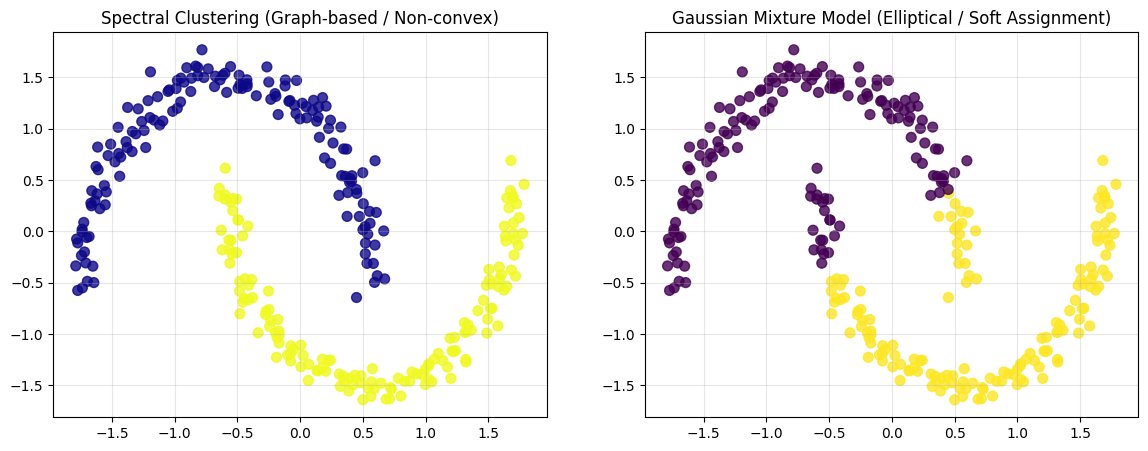

Sample GMM Probabilities (first 5 points):
  Point 0: P(Cluster 0) = 0.3780, P(Cluster 1) = 0.6220
  Point 1: P(Cluster 0) = 0.0474, P(Cluster 1) = 0.9526
  Point 2: P(Cluster 0) = 0.0005, P(Cluster 1) = 0.9995
  Point 3: P(Cluster 0) = 1.0000, P(Cluster 1) = 0.0000
  Point 4: P(Cluster 0) = 0.9999, P(Cluster 1) = 0.0001

Points with high uncertainty (0.3 < P < 0.7): 12 points
GMM BIC Score: 1597.121


In [7]:
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture

# 1. Dataset Moons
X_adv, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X_adv = StandardScaler().fit_transform(X_adv)

# 2. Fit Spectral Clustering vs GMM
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X_adv)

gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X_adv)

# Visualisasi Perbandingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X_adv[:, 0], X_adv[:, 1], c=y_spectral, cmap='plasma', s=50, alpha=0.8)
ax1.set_title("Spectral Clustering (Graph-based / Non-convex)")
ax1.grid(True, alpha=0.3)

ax2.scatter(X_adv[:, 0], X_adv[:, 1], c=y_gmm, cmap='viridis', s=50, alpha=0.8)
ax2.set_title("Gaussian Mixture Model (Elliptical / Soft Assignment)")
ax2.grid(True, alpha=0.3)

plt.show()

# 3. Analisis Probabilitas Posterior pada GMM
probs = gmm.predict_proba(X_adv)
print("Sample GMM Probabilities (first 5 points):")
for i in range(5):
    print(f"  Point {i}: P(Cluster 0) = {probs[i,0]:.4f}, P(Cluster 1) = {probs[i,1]:.4f}")

uncertain_points = np.sum((probs[:, 0] > 0.3) & (probs[:, 0] < 0.7))
print(f"\nPoints with high uncertainty (0.3 < P < 0.7): {uncertain_points} points")
print(f"GMM BIC Score: {gmm.bic(X_adv):.3f}")

- Grafik Spectral Clustering (Kiri): Memisahkan dua bulan sabit secara sempurna ($150$ vs $150$ sampel) karena bekerja pada manifold graf kemiripan.

- Grafik GMM (Kanan): GMM memaksakan pemodelan dua elips Gaussian, sehingga garis pemisahnya terpotong lurus di tengah memotong kedua kurva bulan sabit.

- Probabilitas Posterior GMM: Menampilkan tingkat kepastian model. Titik di dalam area aman kluster memiliki probabilitas mendekati $1.0$ (seperti Point 3: $P=1.0000$), sedangkan titik yang berada di zona perbatasan memudar kepastiannya (seperti Point 0: $P_0=0.3780, P_1=0.6220$). Terdapat $12$ titik yang berada dalam zona keraguan ($0.3 < P < 0.7$).